# Ground states with DMRG

An `HSMPO` can do more than evaluate a fixed circuit: it can also search for the ground state of a Hamiltonian with the density matrix renormalization group (DMRG). In this tutorial you will learn how to define a Hamiltonian, run `minimize_expectation`, check the result against exact diagonalization, and choose the bond dimension.

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
from qibo.config import log
from qibo.hamiltonians import SymbolicHamiltonian
from qibo.symbols import X, Y, Z

from mpstab import HSMPO
from mpstab.models.ansatze import HardwareEfficient
sys.path.append("../..")  # examples/, home of the plot style
from plotting import COLORS, set_style

set_style()
log.setLevel("WARNING")  # silence qibo's backend message
np.random.seed(42)

## The XXZ chain

We study the open XXZ chain with anisotropy $\Delta = 2$,

$$H = \sum_{i=1}^{n-1} \left(X_i X_{i+1} + Y_i Y_{i+1} + \Delta\, Z_i Z_{i+1}\right).$$

The easiest way to write it is as a qibo `SymbolicHamiltonian`, built from Pauli symbols. The same object will give us the exact ground-state energy on a small chain.

In [2]:
def xxz(nqubits, delta=2.0):
    form = sum(
        X(i) * X(i + 1) + Y(i) * Y(i + 1) + delta * Z(i) * Z(i + 1)
        for i in range(nqubits - 1)
    )
    return SymbolicHamiltonian(form)

`minimize_expectation` also accepts simpler formats, which are handy for short Hamiltonians:

| Format | Example | Meaning |
|---|---|---|
| Pauli string | `"ZZII"` | one term with coefficient 1 |
| list of strings | `["ZZII", "IIXX"]` | sum of terms with coefficient 1 |
| dict | `{"ZZII": 1.0, "IIXX": 0.5}` | weighted sum of terms |
| `SymbolicHamiltonian` | `X(0) * X(1) + 0.5 * Z(0)` | any qibo Hamiltonian, constants included |

## A first optimization

DMRG needs a starting state. We take a random two-layer hardware-efficient circuit and wrap it in an `HSMPO`: the circuit's MPS is the initial guess. Before the optimization, its energy is far from the ground state.

In [3]:
n = 10
hamiltonian = xxz(n)
hsmpo = HSMPO(HardwareEfficient(nqubits=n, nlayers=2), progress=False)
print(f"initial energy: {hsmpo.expectation(hamiltonian):.4f}")

initial energy: 0.7666


Now we call `minimize_expectation`. The main options are:

| Option | Default | Meaning |
|---|---|---|
| `bond_dims` | `[10, 20, 50, 100, 200]` | maximum bond dimension per sweep, or one value for all sweeps |
| `max_sweeps` | `10` | maximum number of DMRG sweeps |
| `tol` | `1e-6` | stop when the energy changes less than this between sweeps |
| `cutoff` | `1e-9` | singular-value truncation cutoff |
| `verbosity` | `1` | DMRG printout, from 0 (silent) to 2 |

Here we let the bond dimension grow sweep by sweep.

In [4]:
result = hsmpo.minimize_expectation(
    hamiltonian, bond_dims=[2, 4, 8, 16], max_sweeps=10, tol=1e-10, verbosity=0
)
print(f"DMRG energy: {result['energy']:.8f}")
print(f"converged:   {result['converged']} after {result['num_sweeps']} sweeps")

DMRG energy: -23.33072544
converged:   True after 6 sweeps


The result is a dict with the `energy`, the optimized MPS (`ground_state`), a `converged` flag, the number of sweeps and the `energy_history`. The `HSMPO` itself now holds the optimized state, so its expectation values refer to the ground state.

In [5]:
print(f"<H> on the HSMPO: {hsmpo.expectation(hamiltonian):.8f}")

<H> on the HSMPO: -23.33072544


## Comparison with exact diagonalization

Ten qubits is small enough to diagonalize the Hamiltonian exactly. We compare the energy after each sweep with the exact value: the error drops by orders of magnitude in a few sweeps, then flattens at about $10^{-8}$, the truncation error left by a bond dimension of 16.

exact energy: -23.33072546


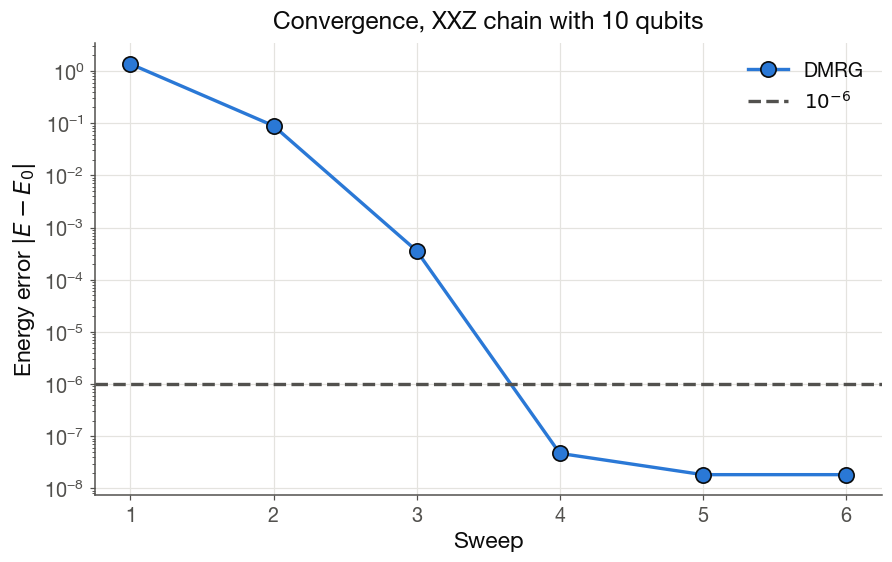

In [6]:
exact = np.linalg.eigvalsh(hamiltonian.matrix)[0]
errors = np.abs(np.array(result["energy_history"]) - exact)
sweeps = np.arange(1, len(errors) + 1)
print(f"exact energy: {exact:.8f}")

plt.semilogy(sweeps, errors, "o-", label="DMRG")
plt.axhline(1e-6, color=COLORS["gray"], ls="--", label="$10^{-6}$")
plt.xlabel("Sweep")
plt.ylabel("Energy error $|E - E_0|$")
plt.title(f"Convergence, XXZ chain with {n} qubits")
plt.legend()
plt.show()

## How large a bond dimension?

The bond dimension sets the accuracy of the MPS. We restart from a fresh circuit for each value and keep it fixed during all sweeps. Gapped chains like this one need only a modest bond dimension.

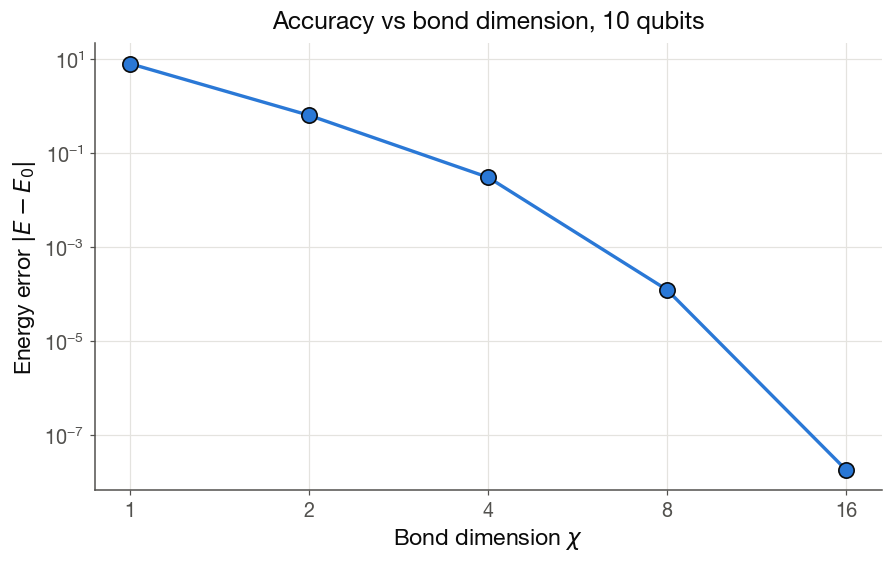

In [7]:
bond_dims = [1, 2, 4, 8, 16]
errors = []
for chi in bond_dims:
    hsmpo = HSMPO(HardwareEfficient(nqubits=n, nlayers=2), progress=False)
    result = hsmpo.minimize_expectation(
        hamiltonian, bond_dims=chi, max_sweeps=10, tol=1e-10, verbosity=0
    )
    errors.append(abs(result["energy"] - exact))

plt.semilogy(bond_dims, errors, "o-", color=COLORS["blue"])
plt.xscale("log", base=2)
plt.xticks(bond_dims, bond_dims)
plt.xlabel("Bond dimension $\\chi$")
plt.ylabel("Energy error $|E - E_0|$")
plt.title(f"Accuracy vs bond dimension, {n} qubits")
plt.show()

## A larger chain

Exact diagonalization is out of reach for 30 qubits, but DMRG is not. We repeat the bond-dimension scan and watch the energy saturate: once it stops changing, the bond dimension is large enough. We also record the run time, which grows with the bond dimension.

In [8]:
n = 30
hamiltonian = xxz(n)
bond_dims = [4, 8, 16, 32]
energies, times = [], []
for chi in bond_dims:
    start = time.perf_counter()
    hsmpo = HSMPO(HardwareEfficient(nqubits=n, nlayers=2), progress=False)
    result = hsmpo.minimize_expectation(hamiltonian, bond_dims=chi, max_sweeps=8, verbosity=0)
    energies.append(result["energy"])
    times.append(time.perf_counter() - start)
    print(f"chi = {chi:2d}   E = {energies[-1]:.6f}   time = {times[-1]:.1f} s")

chi =  4   E = -72.406917   time = 0.8 s


chi =  8   E = -72.495348   time = 1.4 s


chi = 16   E = -72.509999   time = 3.5 s


chi = 32   E = -72.510102   time = 10.1 s


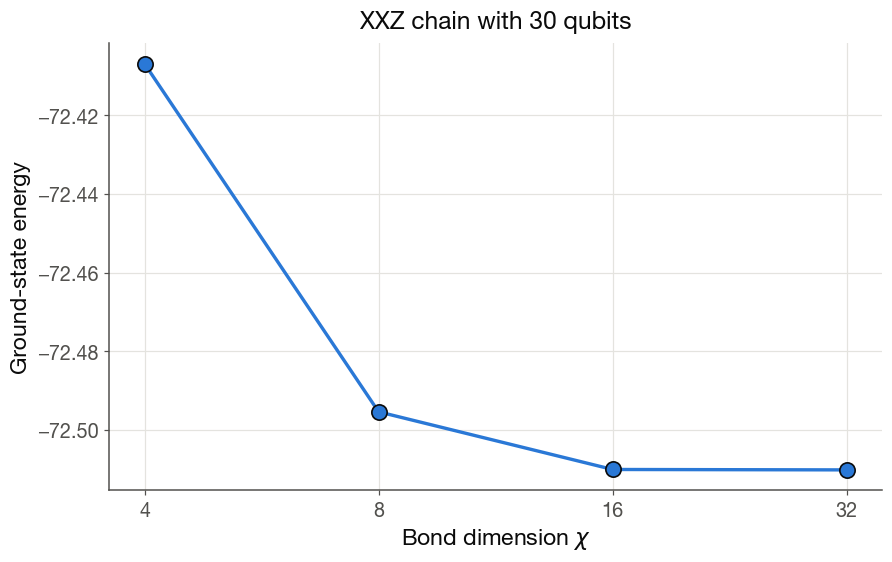

In [9]:
plt.plot(bond_dims, energies, "o-", color=COLORS["blue"])
plt.xscale("log", base=2)
plt.xticks(bond_dims, bond_dims)
plt.xlabel("Bond dimension $\\chi$")
plt.ylabel("Ground-state energy")
plt.title(f"XXZ chain with {n} qubits")
plt.show()

## Summary

- Write the Hamiltonian as a Pauli string, a list, a dict or a qibo `SymbolicHamiltonian`.
- Wrap a starting circuit in an `HSMPO` and call `minimize_expectation`; the `HSMPO` keeps the optimized state.
- Check the energy history and increase the bond dimension until the energy stops changing.

Before DMRG runs, every Hamiltonian term is moved through the Clifford part of the circuit, so the MPS only has to describe what the Clifford gates cannot.